# **Practical 5**

/tmp/ipykernel_552/1123833962.py:22: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  data.fillna(method='ffill', inplace=True)


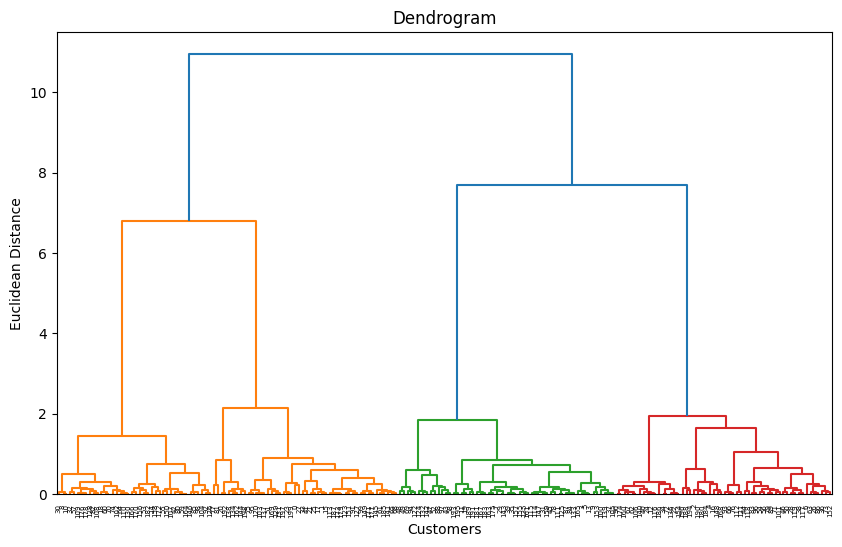

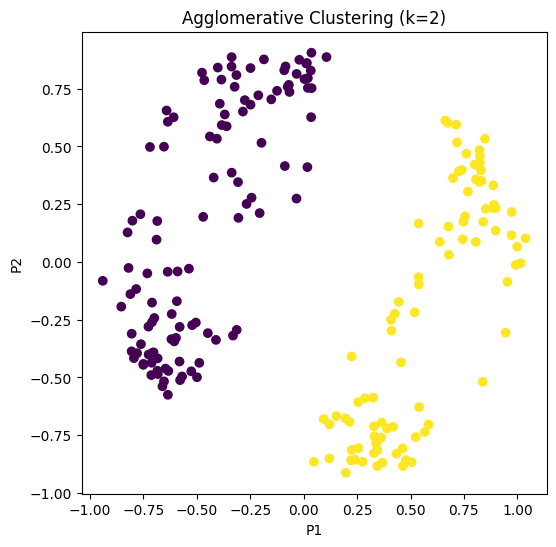

Silhouette Score for k=2: 0.4780


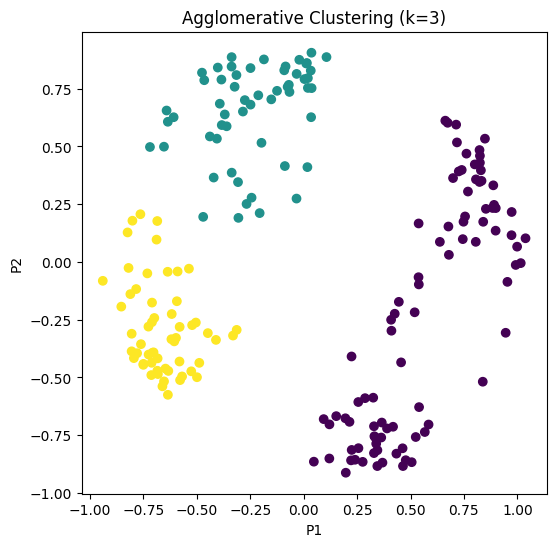

Silhouette Score for k=3: 0.5419


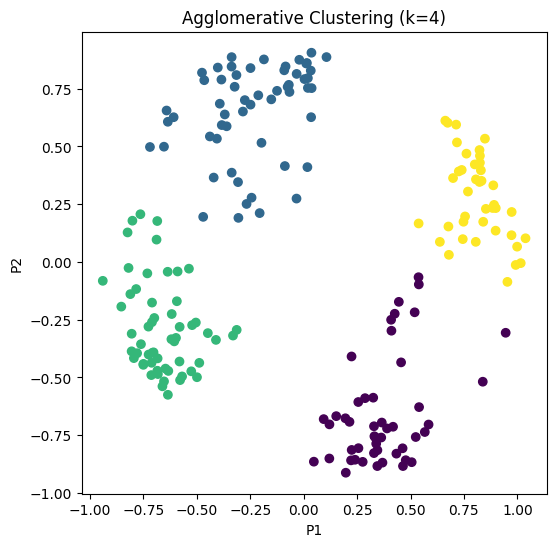

Silhouette Score for k=4: 0.6477


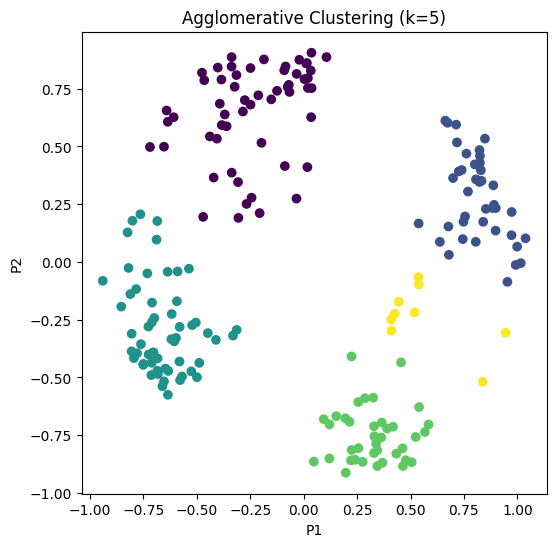

Silhouette Score for k=5: 0.6079


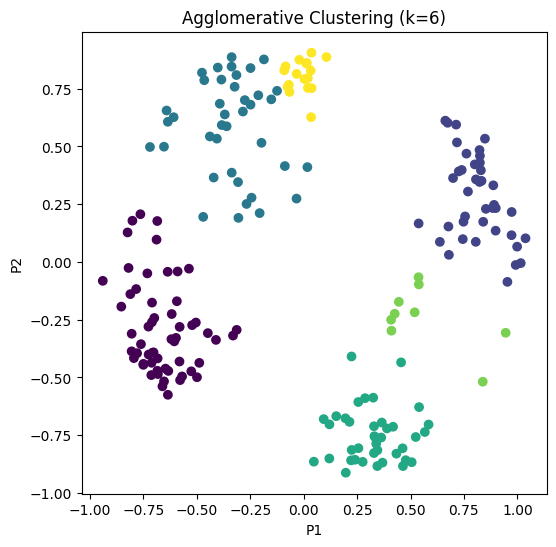

Silhouette Score for k=6: 0.5333


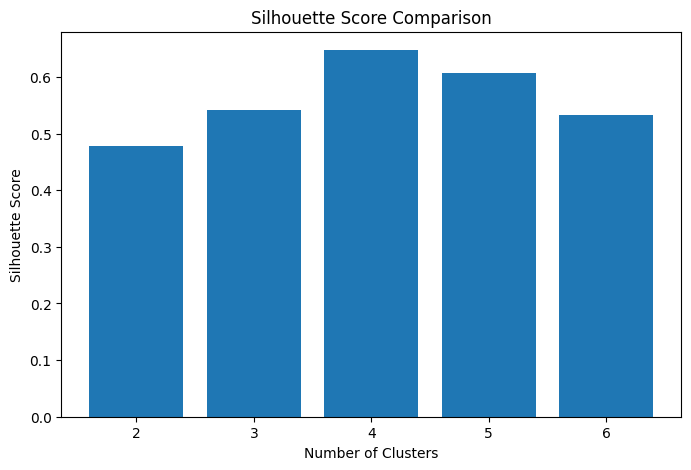


Optimal Number of Clusters = 4


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler, normalize
from sklearn.decomposition import PCA
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

from scipy.cluster.hierarchy import dendrogram, linkage

# =========================
# Step 1 : Load Dataset
# =========================

data = pd.read_csv("/content/Mall_Customers.csv")

# Remove Customer ID
data = data.drop("CustomerID", axis=1)

# Fill missing values
data.fillna(method='ffill', inplace=True)

# Convert 'Gender' column to numerical using one-hot encoding
data = pd.get_dummies(data, columns=['Gender'], drop_first=True)

# =========================
# Step 2 : Preprocessing
# =========================

scaler = StandardScaler()
scaled_data = scaler.fit_transform(data)

normalized_data = normalize(scaled_data)

# =========================
# Step 3 : PCA
# =========================

pca = PCA(n_components=2)

principal = pca.fit_transform(normalized_data)

X = pd.DataFrame(principal, columns=['P1', 'P2'])

# =========================
# Step 4 : Dendrogram
# =========================

plt.figure(figsize=(10,6))

linked = linkage(X, method='ward')

dendrogram(linked)

plt.title("Dendrogram")
plt.xlabel("Customers")
plt.ylabel("Euclidean Distance")
plt.show()

# =========================
# Step 5 : Clustering
# =========================

k_values = [2,3,4,5,6]

silhouette_scores = []

for k in k_values:

    model = AgglomerativeClustering(
        n_clusters=k,
        linkage='ward'
    )

    labels = model.fit_predict(X)

    score = silhouette_score(X, labels)

    silhouette_scores.append(score)

    plt.figure(figsize=(6,6))

    plt.scatter(
        X['P1'],
        X['P2'],
        c=labels
    )

    plt.title(f"Agglomerative Clustering (k={k})")
    plt.xlabel("P1")
    plt.ylabel("P2")

    plt.show()

    print(f"Silhouette Score for k={k}: {score:.4f}")

# =========================
# Step 6 : Compare Scores
# =========================

plt.figure(figsize=(8,5))

plt.bar(k_values, silhouette_scores)

plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")

plt.title("Silhouette Score Comparison")

plt.show()

best_k = k_values[np.argmax(silhouette_scores)]

print("\nOptimal Number of Clusters =", best_k)